# EfficientNet_B0 — GTSRB

In [ ]:
!pip -q install kagglehub

import kagglehub

dataset_path = kagglehub.dataset_download(
    "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
)

print("Dataset location:", dataset_path)

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Dataset location: /kaggle/input/gtsrb-german-traffic-sign


In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

GPU available: True
GPU name: Tesla T4


In [ ]:
import os
import csv
import json
import random
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
print('PyTorch:', torch.__version__)

Device: cuda
PyTorch: 2.11.0+cu130


## Configuration

In [ ]:
DATA_SOURCE = 'kaggle_local'
KAGGLE_PATH = '/kaggle/input/gtsrb-german-traffic-sign'
KAGGLE_DATASET = 'meowmeowmeowmeowmeow/gtsrb-german-traffic-sign'

MOUNT_DRIVE = False
DATA_ROOT = Path('/content/gtsrb_data')
OUTPUT_ROOT = Path('/content/EN3150_A03')
SPLIT_CSV = OUTPUT_ROOT / 'gtsrb_splits.csv'  # Reuse this file in both notebooks
INCLUDE_ORIGINAL_TEST = True     # Use False if the custom CNNs used only the original training partition

IMAGE_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 15
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 6
NUM_WORKERS = 2
NUM_CLASSES = 43

if MOUNT_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')

DATA_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
SPLIT_CSV = Path(SPLIT_CSV)
SPLIT_CSV.parent.mkdir(parents=True, exist_ok=True)

## GTSRB dataset

In [ ]:
def locate_kaggle_root(path):
    path = Path(path).expanduser()
    if not path.exists():
        raise FileNotFoundError(f'Kaggle path does not exist: {path}')
    if path.is_file():
        if path.suffix.lower() != '.zip':
            raise ValueError('KAGGLE_PATH must be a dataset directory or .zip archive.')
        unpack_dir = DATA_ROOT / 'kaggle_extracted'
        if not (unpack_dir / '.extracted').exists():
            unpack_dir.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(path) as archive:
                archive.extractall(unpack_dir)
            (unpack_dir / '.extracted').touch()
        path = unpack_dir

    candidates = [path]
    candidates.extend(p for p in path.iterdir() if p.is_dir())
    candidates.extend(p for p in path.glob('*/*') if p.is_dir())
    for root in candidates:
        if (root / 'Train').is_dir() and (root / 'Test.csv').is_file():
            return root
    raise FileNotFoundError('Could not locate Train/ and Test.csv inside the Kaggle dataset.')


def kaggle_records(root, include_test=True):
    root = Path(root)
    samples = []
    train_csv = root / 'Train.csv'
    if train_csv.exists():
        train_rows = pd.read_csv(train_csv)
        if not {'Path', 'ClassId'}.issubset(train_rows.columns):
            raise ValueError('Train.csv needs Path and ClassId columns.')
        for row in train_rows.itertuples(index=False):
            path = root / str(row.Path).replace('\\', '/')
            samples.append((path, int(row.ClassId)))
    else:
        for folder in sorted((root / 'Train').iterdir(), key=lambda p: p.name):
            if folder.is_dir() and folder.name.isdigit():
                for path in sorted(folder.rglob('*')):
                    if path.suffix.lower() in {'.png', '.ppm', '.jpg', '.jpeg'}:
                        samples.append((path, int(folder.name)))

    if include_test:
        test_rows = pd.read_csv(root / 'Test.csv')
        if not {'Path', 'ClassId'}.issubset(test_rows.columns):
            raise ValueError('Test.csv needs Path and ClassId columns.')
        for row in test_rows.itertuples(index=False):
            path = root / str(row.Path).replace('\\', '/')
            samples.append((path, int(row.ClassId)))
    return samples


def torchvision_records(root, include_test=True):
    training = datasets.GTSRB(root=str(root), split='train', download=True)
    samples = [(Path(p), int(label)) for p, label in training._samples]
    if include_test:
        testing = datasets.GTSRB(root=str(root), split='test', download=True)
        samples.extend((Path(p), int(label)) for p, label in testing._samples)
    return samples


if DATA_SOURCE == 'torchvision':
    source_root = DATA_ROOT
    raw_records = torchvision_records(source_root, INCLUDE_ORIGINAL_TEST)
elif DATA_SOURCE == 'kaggle_local':
    source_root = locate_kaggle_root(KAGGLE_PATH)
    raw_records = kaggle_records(source_root, INCLUDE_ORIGINAL_TEST)
elif DATA_SOURCE == 'kaggle_download':
    try:
        import kagglehub
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'])
        import kagglehub
    kaggle_dir = kagglehub.dataset_download(KAGGLE_DATASET)
    source_root = locate_kaggle_root(kaggle_dir)
    raw_records = kaggle_records(source_root, INCLUDE_ORIGINAL_TEST)
else:
    raise ValueError('DATA_SOURCE must be torchvision, kaggle_local, or kaggle_download.')

records = pd.DataFrame(
    [(p.relative_to(source_root).as_posix(), int(label), str(p)) for p, label in raw_records],
    columns=['sample_id', 'label', 'path']
).sort_values('sample_id', kind='stable').reset_index(drop=True)

if records.sample_id.duplicated().any():
    raise ValueError('Duplicate sample paths found in the dataset.')
if set(records.label.unique()) != set(range(NUM_CLASSES)):
    raise ValueError('Expected all 43 GTSRB classes (0–42).')
missing = [p for p in records.path if not Path(p).is_file()]
if missing:
    raise FileNotFoundError(f'{len(missing)} image files are missing. Example: {missing[0]}')

print('Data source:', DATA_SOURCE)
print('Images:', len(records), ' | Classes:', records.label.nunique())
print('Original test images included:', INCLUDE_ORIGINAL_TEST)
print(records.label.value_counts().sort_index().to_string())

Data source: kaggle_local
Images: 51839  | Classes: 43
Original test images included: True
label
0      270
1     2940
2     3000
3     1860
4     2640
5     2490
6      570
7     1890
8     1860
9     1950
10    2670
11    1740
12    2790
13    2880
14    1050
15     840
16     570
17    1470
18    1590
19     270
20     450
21     420
22     510
23     660
24     360
25    1980
26     780
27     300
28     690
29     360
30     600
31    1050
32     300
33     899
34     540
35    1590
36     510
37     270
38    2760
39     390
40     450
41     300
42     330


## Train, validation and test splits

In [ ]:
if SPLIT_CSV.exists():
    manifest = pd.read_csv(SPLIT_CSV, dtype={'sample_id': str})
    needed = {'sample_id', 'label', 'split'}
    if not needed.issubset(manifest.columns):
        raise ValueError(f'{SPLIT_CSV} must contain sample_id, label and split columns.')
    if manifest.sample_id.duplicated().any():
        raise ValueError('Duplicate sample_id values in the split manifest.')
    if set(manifest.sample_id) != set(records.sample_id):
        raise ValueError('The saved split manifest does not match the selected dataset. '
                         'Use the same data source and INCLUDE_ORIGINAL_TEST setting, '
                         'or choose a different SPLIT_CSV path.')
    labels_check = records[['sample_id', 'label']].merge(
        manifest[['sample_id', 'label']], on='sample_id', suffixes=('_data', '_saved'))
    if not (labels_check.label_data == labels_check.label_saved).all():
        raise ValueError('Labels in the saved split manifest do not match the dataset.')
    if set(manifest.split.unique()) != {'train', 'val', 'test'}:
        raise ValueError('Split manifest must contain train, val and test labels.')
    print('Using existing split file:', SPLIT_CSV)
else:
    all_idx = np.arange(len(records))
    train_idx, holdout_idx = train_test_split(
        all_idx, test_size=0.30, random_state=SEED, stratify=records.label)
    val_idx, test_idx = train_test_split(
        holdout_idx, test_size=0.50, random_state=SEED,
        stratify=records.label.iloc[holdout_idx])
    manifest = records[['sample_id', 'label']].copy()
    manifest['split'] = ''
    manifest.loc[train_idx, 'split'] = 'train'
    manifest.loc[val_idx, 'split'] = 'val'
    manifest.loc[test_idx, 'split'] = 'test'
    manifest.to_csv(SPLIT_CSV, index=False)
    print('Created split file:', SPLIT_CSV)

records = records.merge(manifest[['sample_id', 'split']], on='sample_id', validate='one_to_one')
print(records.groupby('split').size().reindex(['train', 'val', 'test']))
print('Proportions:')
print((records.groupby('split').size() / len(records)).reindex(['train', 'val', 'test']).round(4))

Created split file: /content/EN3150_A03/gtsrb_splits.csv
split
train    36287
val       7776
test      7776
dtype: int64
Proportions:
split
train    0.70
val      0.15
test     0.15
dtype: float64


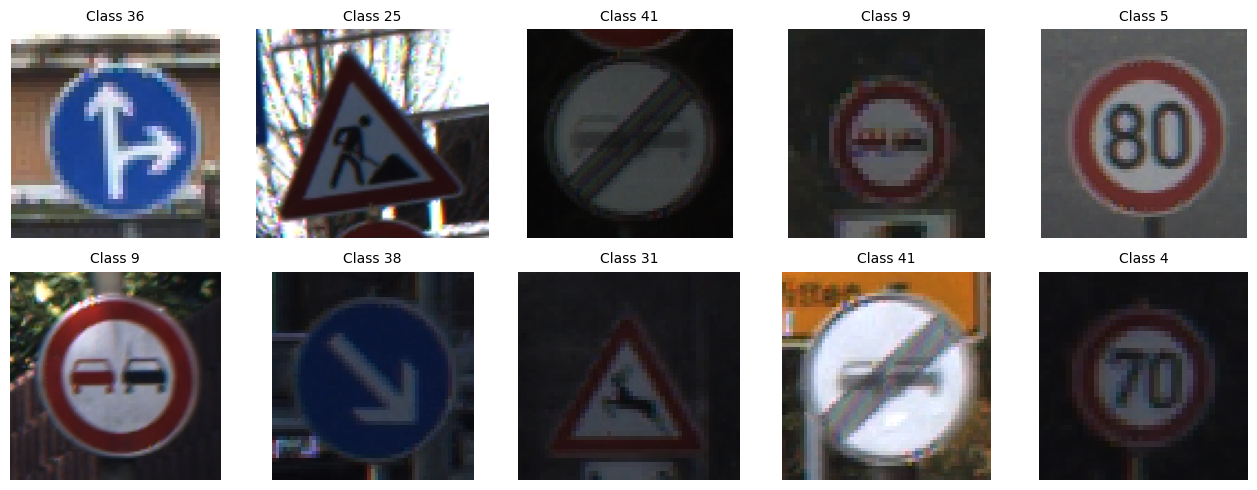

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
example_rows = records[records.split == 'train'].sample(10, random_state=SEED)
for ax, sample in zip(axes.ravel(), example_rows.itertuples()):
    with Image.open(sample.path) as image:
        ax.imshow(image.convert('RGB'))
    ax.set_title(f'Class {sample.label}', fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Data loaders

In [ ]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomAffine(degrees=10, translate=(0.08, 0.08), scale=(0.90, 1.10)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])


class GTSRBPaths(Dataset):
    def __init__(self, frame, transform):
        self.paths = frame.path.tolist()
        self.labels = frame.label.astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = image.convert('RGB')
            x = self.transform(image)
        return x, self.labels[index]


train_set = GTSRBPaths(records[records.split == 'train'], train_transform)
val_set = GTSRBPaths(records[records.split == 'val'], eval_transform)
test_set = GTSRBPaths(records[records.split == 'test'], eval_transform)

loader_options = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == 'cuda'),
    persistent_workers=(NUM_WORKERS > 0),
)
train_loader = DataLoader(train_set, shuffle=True, **loader_options)
val_loader = DataLoader(val_set, shuffle=False, **loader_options)
test_loader = DataLoader(test_set, shuffle=False, **loader_options)

images, labels = next(iter(train_loader))
print('Input shape:', tuple(images.shape))
print('Label range:', int(labels.min()), int(labels.max()))

Input shape: (64, 3, 64, 64)
Label range: 0 42


## Model

In [ ]:
MODEL_NAME = 'EfficientNet_B0'
weights = models.EfficientNet_B0_Weights.DEFAULT
model = models.efficientnet_b0(weights=weights)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model = model.to(device)

model_dir = OUTPUT_ROOT / MODEL_NAME
model_dir.mkdir(parents=True, exist_ok=True)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print('Model:', MODEL_NAME)
print('Total parameters:', f'{total_params:,}')
print('Trainable parameters:', f'{trainable_params:,}')
print('Input resolution:', f'{IMAGE_SIZE}x{IMAGE_SIZE}')

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 144MB/s]


Model: EfficientNet_B0
Total parameters: 4,062,631
Trainable parameters: 4,062,631
Input resolution: 64x64


## Fine-tuning

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
use_amp = (device.type == 'cuda')
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)


def epoch_pass(data_loader, training):
    model.train(training)
    running_loss = 0.0
    running_correct = 0
    n_seen = 0

    for x, y in data_loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        running_loss += loss.item() * y.size(0)
        running_correct += (logits.argmax(1) == y).sum().item()
        n_seen += y.size(0)

    return running_loss / n_seen, running_correct / n_seen


history = []
best_val_acc = -1.0
bad_epochs = 0
best_path = model_dir / 'best_model.pth'

for epoch in range(1, EPOCHS + 1):
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()

    train_loss, train_acc = epoch_pass(train_loader, training=True)
    val_loss, val_acc = epoch_pass(val_loader, training=False)
    scheduler.step()

    if device.type == 'cuda':
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    history.append({
        'epoch': epoch,
        'train_loss': train_loss,
        'train_accuracy': train_acc,
        'val_loss': val_loss,
        'val_accuracy': val_acc,
        'epoch_seconds': elapsed,
    })

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        bad_epochs = 0
        torch.save(model.state_dict(), best_path)
    else:
        bad_epochs += 1

    print(f'Epoch {epoch:02d}/{EPOCHS}  '
          f'train loss {train_loss:.4f}  train acc {train_acc:.4%}  '
          f'val loss {val_loss:.4f}  val acc {val_acc:.4%}  '
          f'time {elapsed:.1f}s')

    if bad_epochs >= PATIENCE:
        print(f'Early stopping at epoch {epoch}.')
        break

history_df = pd.DataFrame(history)
history_df.to_csv(model_dir / 'training_history.csv', index=False)
model.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
print('Best validation accuracy:', f'{best_val_acc:.4%}')

Epoch 01/15  train loss 1.6678  train acc 54.8764%  val loss 0.4650  val acc 86.5098%  time 110.4s
Epoch 02/15  train loss 0.3656  train acc 88.7370%  val loss 0.0920  val acc 97.5309%  time 60.9s
Epoch 03/15  train loss 0.1598  train acc 95.1911%  val loss 0.0386  val acc 98.8683%  time 60.9s
Epoch 04/15  train loss 0.0950  train acc 97.1450%  val loss 0.0202  val acc 99.4599%  time 60.4s
Epoch 05/15  train loss 0.0666  train acc 97.9690%  val loss 0.0136  val acc 99.6013%  time 61.0s
Epoch 06/15  train loss 0.0503  train acc 98.4843%  val loss 0.0112  val acc 99.7042%  time 61.0s
Epoch 07/15  train loss 0.0412  train acc 98.7351%  val loss 0.0067  val acc 99.8071%  time 60.9s
Epoch 08/15  train loss 0.0306  train acc 99.0796%  val loss 0.0052  val acc 99.8714%  time 60.8s
Epoch 09/15  train loss 0.0252  train acc 99.2063%  val loss 0.0060  val acc 99.8071%  time 60.9s
Epoch 10/15  train loss 0.0223  train acc 99.3469%  val loss 0.0039  val acc 99.9100%  time 61.6s
Epoch 11/15  train 

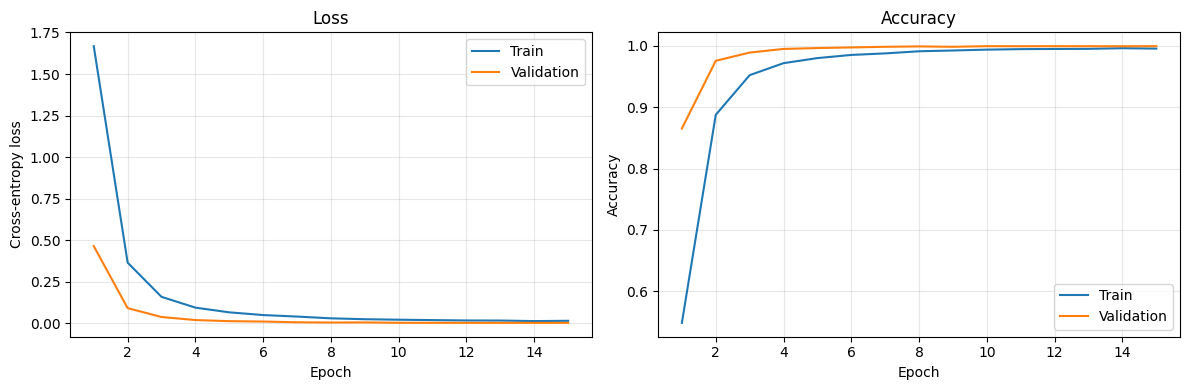

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df.epoch, history_df.train_loss, label='Train')
axes[0].plot(history_df.epoch, history_df.val_loss, label='Validation')
axes[0].set(xlabel='Epoch', ylabel='Cross-entropy loss', title='Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_df.epoch, history_df.train_accuracy, label='Train')
axes[1].plot(history_df.epoch, history_df.val_accuracy, label='Validation')
axes[1].set(xlabel='Epoch', ylabel='Accuracy', title='Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(model_dir / 'training_curves.png', dpi=160, bbox_inches='tight')
plt.show()

## Test evaluation

In [ ]:
model.eval()
y_true = []
y_pred = []

with torch.inference_mode():
    for x, y in test_loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            logits = model(x)
        y_true.extend(y.numpy().tolist())
        y_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())

test_accuracy = accuracy_score(y_true, y_pred)
class_report = classification_report(
    y_true, y_pred, labels=list(range(NUM_CLASSES)),
    output_dict=True, zero_division=0)
report_df = pd.DataFrame(class_report).T
report_df.to_csv(model_dir / 'classification_report.csv')

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
pd.DataFrame(cm, index=range(NUM_CLASSES), columns=range(NUM_CLASSES)).to_csv(
    model_dir / 'confusion_matrix.csv')

print(f'Test accuracy: {test_accuracy:.4%}')
print(f'Macro precision: {class_report["macro avg"]["precision"]:.4f}')
print(f'Macro recall: {class_report["macro avg"]["recall"]:.4f}')
print(f'Macro F1: {class_report["macro avg"]["f1-score"]:.4f}')
print(f'Weighted precision: {class_report["weighted avg"]["precision"]:.4f}')
print(f'Weighted recall: {class_report["weighted avg"]["recall"]:.4f}')
display(report_df.round(4))

Test accuracy: 99.8200%
Macro precision: 0.9989
Macro recall: 0.9991
Macro F1: 0.9990
Weighted precision: 0.9982
Weighted recall: 0.9982


,precision,recall,f1-score,support
0,1.0000,1.0000,1.0000,40.0000
1,0.9955,0.9955,0.9955,441.0000
2,0.9912,1.0000,0.9956,450.0000
3,1.0000,0.9928,0.9964,279.0000
4,1.0000,0.9924,0.9962,396.0000
5,0.9946,0.9920,0.9933,373.0000
6,1.0000,1.0000,1.0000,86.0000
7,1.0000,0.9929,0.9965,283.0000
8,0.9894,1.0000,0.9947,279.0000
9,1.0000,1.0000,1.0000,292.0000


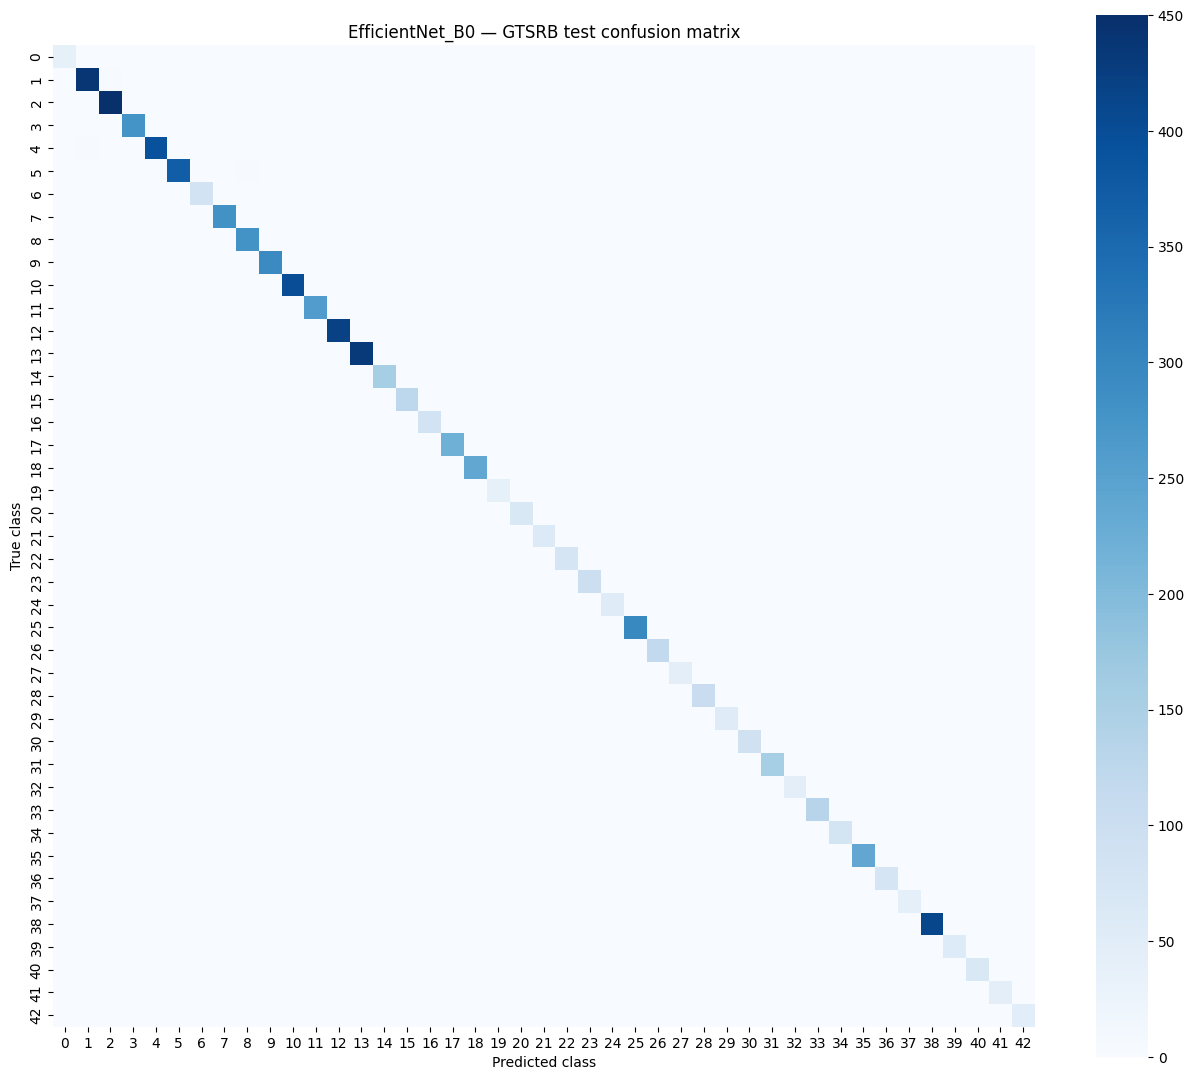

In [ ]:
plt.figure(figsize=(13, 11))
sns.heatmap(cm, cmap='Blues', square=True, cbar=True, xticklabels=range(NUM_CLASSES),
            yticklabels=range(NUM_CLASSES), annot=False)
plt.xlabel('Predicted class')
plt.ylabel('True class')
plt.title(f'{MODEL_NAME} — GTSRB test confusion matrix')
plt.tight_layout()
plt.savefig(model_dir / 'confusion_matrix.png', dpi=180, bbox_inches='tight')
plt.show()

## Model statistics

In [ ]:
checkpoint_mb = best_path.stat().st_size / (1024 ** 2)
avg_epoch_seconds = float(history_df.epoch_seconds.mean())

# Average inference latency per image on the selected device (batch inference).
model.eval()
latency_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False,
                            num_workers=0, pin_memory=(device.type == 'cuda'))
warmup_batches = 3
measure_batches = 20
measured_images = 0

with torch.inference_mode():
    for index, (x, _) in enumerate(latency_loader):
        if index >= warmup_batches + measure_batches:
            break
        x = x.to(device, non_blocking=True)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            _ = model(x)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        if index >= warmup_batches:
            if index == warmup_batches:
                total_infer_seconds = 0.0
            total_infer_seconds += time.perf_counter() - start
            measured_images += x.shape[0]

latency_ms = 1000 * total_infer_seconds / measured_images if measured_images else float('nan')

summary = {
    'model': MODEL_NAME,
    'dataset': 'GTSRB',
    'data_source': DATA_SOURCE,
    'include_original_test': INCLUDE_ORIGINAL_TEST,
    'input_resolution': f'{IMAGE_SIZE}x{IMAGE_SIZE}',
    'train_samples': len(train_set),
    'val_samples': len(val_set),
    'test_samples': len(test_set),
    'total_parameters': total_params,
    'trainable_parameters': trainable_params,
    'model_size_MB': round(checkpoint_mb, 3),
    'epochs_trained': len(history_df),
    'mean_epoch_seconds': round(avg_epoch_seconds, 2),
    'test_accuracy': round(float(test_accuracy), 6),
    'macro_precision': round(float(class_report['macro avg']['precision']), 6),
    'macro_recall': round(float(class_report['macro avg']['recall']), 6),
    'macro_f1': round(float(class_report['macro avg']['f1-score']), 6),
    'inference_ms_per_image': round(float(latency_ms), 4),
    'device': str(device),
}

with open(model_dir / 'metrics.json', 'w') as f:
    json.dump(summary, f, indent=2)

summary_df = pd.DataFrame([summary])
summary_df.to_csv(model_dir / 'summary.csv', index=False)
display(summary_df.T.rename(columns={0: 'Value'}))
print('Saved results to:', model_dir)

,Value
model,EfficientNet_B0
dataset,GTSRB
data_source,kaggle_local
include_original_test,True
input_resolution,64x64
train_samples,36287
val_samples,7776
test_samples,7776
total_parameters,4062631
trainable_parameters,4062631


Saved results to: /content/EN3150_A03/EfficientNet_B0
